In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/1
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第1章 PCの仕組みとハローワールド — 演習問題 (*Chapter 1 Comprehensive Exercises*)

名著『**ゼロからのOS自作入門**』（内田公太 著）第1章「PCの仕組みとハローワールド」で学んだ、UEFIブート、PE32+/COFFバイナリ構造、Microsoft x64呼出規約、Linuxブロックデバイス、WSL/QEMU環境、CPUリセットベクタ、UTF-16LE文字列、MBR vs GPTアドレッシング数理、Freestandingツールチェーン、および最小C言語UEFIアプリの全理論と実装技術を総動員して解く総合演習問題です。

---

## 🗺️ 第1章 全体像・知識ロードマップ

```mermaid
graph TD
    subgraph S1["1.1〜1.4: 起動とブート環境"]
        A["1.1 ハローワールド<br/>(PE32+ / x64 ABI / バイナリ合成)"] --> B["1.2 USBメモリ探索<br/>(/dev/sdX / major:minor / FAT32)"]
        B --> C["1.3 WSL環境構築<br/>(WSL1 vs WSL2 / USB/IP)"]
        C --> D["1.4 QEMU + OVMF<br/>(仮想PC / FAT32オンザフライ)"]
    end

    subgraph S2["1.5〜1.7: ハードウェア & ファームウェア理論"]
        D --> E["1.5 ブートシーケンス<br/>(0xFFFFFFF0 / UEFI PI 5大フェーズ)"]
        E --> F["1.6 実験・観察マインド<br/>(UTF-16LE改変 / OODAループ)"]
        F --> G["1.7 UEFI BIOSによる起動<br/>(リアルモード vs Long Mode / MBR vs GPT 8ZiB)"]
    end

    subgraph S3["1.8〜1.9: コンパイラと最小C実装"]
        G --> H["1.8 OSを作る道具<br/>(Freestanding / Clang 4大フラグ)"]
        H --> I["1.9 C言語でハローワールド<br/>(EFI_SYSTEM_TABLE / PE32+ vs ELF64)"]
    end

    I ==> J["第1章 総合演習問題<br/>(穴埋め・数理・C++20・10問クイズ・レーダー)"]

    style A fill:#E3F2FD,stroke:#1565C0,stroke-width:2px
    style E fill:#FFF3E0,stroke:#E65100,stroke-width:2px
    style I fill:#E8F5E9,stroke:#2E7D32,stroke-width:2px
    style J fill:#FCE4EC,stroke:#C2185B,stroke-width:3px
```

---

## 🎯 演習の到達目標 (Learning Objectives)

1. **PE32+ バイナリ構造 & x64 ABI 規約の完全把握**:
   - DOSヘッダ (`0x5A4D`)、PEシグネチャ (`0x00004550`)、Optional Header Magic (`0x020B`) の同定。
   - Microsoft x64 呼出規約における引数レジスタ (`RCX, RDX, R8, R9`)、32バイトのシャドウスペース、16バイト境界スタック整列の役割を説明できる。
2. **ストレージ・ハードウェア数理の完全導出**:
   - MBR（32ビットLBA $	imes$ 512B = 2TiB）と GPT（64ビットLBA $	imes$ 512B = 8ZiB）の容量上限を数理的に導出できる。
   - Linux の `dev_t`（メジャー番号 12ビット、マイナー番号 20ビット）のビット演算を自在に行える。
3. **UEFI 構造体オフセット & 最小 C 実装の理解**:
   - 64ビット `EFI_SYSTEM_TABLE` における `ConOut`（オフセット 64バイト）および `OutputString`（オフセット 8バイト）のメモリ配置を正しく計算できる。
4. **C++20 スタンドアロン検証コードと自己採点クイズ**:
   - ホスト側 C++20 で実装された PE32+ パーサ、x64 ABI フレームシミュレータ、SystemTable レイアウトを対話型コンパイル実行し、全節網羅の10問クイズで理解度 80% 以上を達成する。


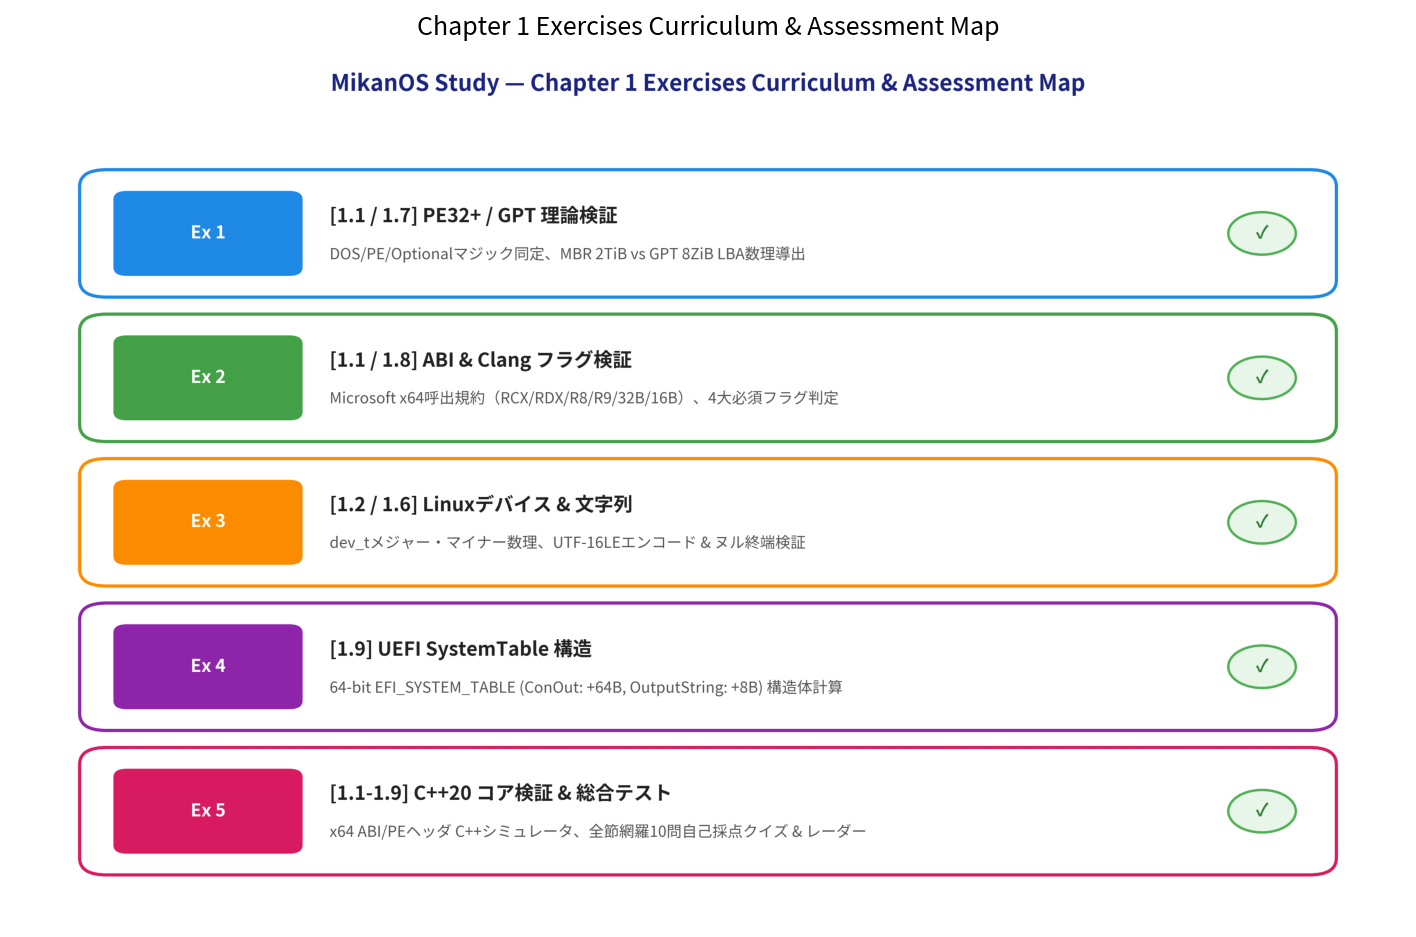

In [2]:
import matplotlib.pyplot as plt
from PIL import Image
from common import plot_chapter1_exercises_summary

# 第1章演習カリキュラムマップの生成と表示
fig_path = "result/fig1_ex1_exercises_summary.png"
plot_chapter1_exercises_summary(fig_path)

img = Image.open(fig_path)
plt.figure(figsize=(12, 7.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Chapter 1 Exercises Curriculum & Assessment Map", fontsize=12, pad=10)
plt.show()


---

## 1. 理論・概念の穴埋め演習 (Theory & Architecture Exercises)

### 問題 1-1: PE32+ ヘッダマジックとシグネチャの同定 (節 1.1)

64ビット UEFI アプリケーション（`BOOTX64.EFI`）のバイナリ構造において、以下の3つの必須定数を 16進整数（例: `0x1234`）で解答してください：
- `dos_magic`: DOSヘッダ先頭の 2バイトマジックナンバー（ASCIIで `"MZ"`）
- `pe_signature`: PEヘッダ先頭の 4バイトシグネチャ（ASCIIで `"PE\0\0"`）
- `optional_magic`: PE32+（64ビット）Optional Header 先頭の 2バイトマジックナンバー


In [3]:
from common import Chapter1TheoryValidator

# === 問題 1-1 解答セル ===
my_pe_magics = {
    "dos_magic": 0x5A4D,          # 'MZ' (0x5A4D)
    "pe_signature": 0x00004550,    # 'PE\0\0' (0x00004550)
    "optional_magic": 0x020B,      # 64-bit PE32+ (0x020B)
}

# バリデータによる自動採点
is_valid, message = Chapter1TheoryValidator.validate_pe_headers(my_pe_magics)
print(message)
assert is_valid, "問題 1-1 が不正解です。PE32+ヘッダのマジック定数を見直してください。"


正解！PE32+ (64-bit UEFI) のヘッダマジック（MZ: 0x5A4D, PE: 0x4550, Optional: 0x020B）を正しく同定しました。


### 問題 1-2: Microsoft x64 呼出規約とスタック整列 (節 1.1)

x86-64 UEFI ファームウェア環境で採用されている **Microsoft x64 Calling Convention** のレジスタ規約およびスタック境界要件を辞書形式で設定してください：
- `arg1` 〜 `arg4`: 整数第1〜第4引数を渡すレジスタ名（小文字文字列: `"rcx"`, `"rdx"`, `"r8"`, `"r9"` 等）
- `shadow_space_bytes`: 呼び出し側（Caller）がスタック上に確保しなければならないシャドウスペース（バイト数）
- `stack_alignment_bytes`: `call` 命令実行直前のスタックポインタ（RSP）が満たすべき整列境界（バイト数）


In [4]:
# === 問題 1-2 解答セル ===
my_uefi_calling_convention = {
    "arg1": "rcx",
    "arg2": "rdx",
    "arg3": "r8",
    "arg4": "r9",
    "shadow_space_bytes": 32,      # 4引数分 × 8バイト = 32バイト (0x20)
    "stack_alignment_bytes": 16,   # call命令直前で RSP % 16 == 0
}

# バリデータによる自動採点
is_valid, message = Chapter1TheoryValidator.validate_uefi_calling_convention(my_uefi_calling_convention)
print(message)
assert is_valid, "問題 1-2 が不正解です。Microsoft x64 呼出規約の仕様を見直してください。"


正解！Microsoft x64 呼出規約（RCX, RDX, R8, R9, 32Bシャドウスペース, 16Bスタック整列）に完全準拠しています。


### 問題 1-3: Clang フリースタンディング 5大コンパイルフラグ (節 1.8)

ホストOS（Linux/macOS）に依存せず、裸の UEFI ハードウェア上で動作する PE32+ バイナリを Clang でビルドする際に不可欠な **5大必須フラグ** を文字列のリストとして指定してください。


In [5]:
# === 問題 1-3 解答セル ===
my_clang_uefi_flags = [
    "-target x86_64-unknown-windows",  # PE32+/COFF ターゲットトリプル
    "-ffreestanding",                  # ホスト標準ライブラリ遮断
    "-mno-red-zone",                   # 128B Red Zone 無効化（割り込みスタック保護）
    "-fno-stack-protector",            # __stack_chk_guard シンボル未解決防止
    "-fshort-wchar",                   # wchar_t を 16-bit (UTF-16LE) に固定
]

# バリデータによる自動採点
is_valid, message = Chapter1TheoryValidator.validate_clang_uefi_flags(my_clang_uefi_flags)
print(message)
assert is_valid, "問題 1-3 が不正解です。Clang UEFI必須フラグを見直してください。"


正解！Clang UEFIコンパイルの5大必須フラグが完璧に指定されています。


### 問題 1-4: 64-bit EFI_SYSTEM_TABLE と ConOut オフセット (節 1.9)

64ビット UEFI における `EFI_SYSTEM_TABLE` 構造体および `EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL` のメモリ配置に関する以下のオフセット（バイト数）を解答してください：
- `con_out_offset`: `EFI_SYSTEM_TABLE` の先頭からポインタメンバ `ConOut` までのバイトオフセット
- `output_string_offset`: `EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL` 先頭から関数ポインタ `OutputString` までのバイトオフセット


In [6]:
# === 問題 1-4 解答セル ===
my_system_table_offsets = {
    "con_out_offset": 64,         # EFI_TABLE_HEADER(24B) + 8B + 4B + 4B(pad) + 8B + 8B + 8B = 64B (0x40)
    "output_string_offset": 8,    # Reset(8B) の次 -> 8B (0x08)
}

# バリデータによる自動採点
is_valid, message = Chapter1TheoryValidator.validate_system_table_layout(my_system_table_offsets)
print(message)
assert is_valid, "問題 1-4 が不正解です。64ビット SystemTable のアライメントとオフセットを見直してください。"


正解！64ビットUEFI EFI_SYSTEM_TABLE (ConOut: +64B) と OutputString (+8B) のオフセット構造に完全適合しています。


---

## 2. 実践 Python 実装演習 (Practical Verification Exercises)

### 問題 2-1: UTF-16LE エンコーダ & ヌル終端検証関数の実装 (節 1.6)

Python の通常の文字列（Unicode 文字列）を受け取り、UEFI の `ConOut->OutputString` が要求する **UTF-16LE バイト列（リトルエンディアン、末尾に 2バイトの `\x00\x00` ヌル終端）** に変換する関数 `encode_uefi_string(text: str) -> bytes` を完成させてください。


In [7]:
def encode_uefi_string(text: str) -> bytes:
    """Convert a Python string to UTF-16LE byte sequence with 2-byte null terminator."""
    # UTF-16LE でエンコードし、末尾に 2バイトの 0x0000 を追加する
    encoded = text.encode("utf-16le")
    if not encoded.endswith(b"\x00\x00"):
        encoded += b"\x00\x00"
    return encoded


# === テスト検証 ===
sample_text = "Hello, MikanOS!"
uefi_bytes = encode_uefi_string(sample_text)

print(f"文字列: '{sample_text}'")
print(f"エンコードバイト長: {len(uefi_bytes)} bytes")
print(f"16進ダンプ: {uefi_bytes.hex(' ')}")

assert len(uefi_bytes) == (len(sample_text) + 1) * 2, "バイト長が (文字数 + 1) * 2 と一致しません"
assert uefi_bytes.endswith(b"\x00\x00"), "2バイトのヌル終端 \x00\x00 が末尾にありません"
assert uefi_bytes[:2] == b"H\x00", "先頭文字 'H' のリトルエンディアン表現が不正です"
print("✅ 問題 2-1 パス: UTF-16LE エンコーダが正常に動作しています。")


文字列: 'Hello, MikanOS!'
エンコードバイト長: 32 bytes
16進ダンプ: 48 00 65 00 6c 00 6c 00 6f 00 2c 00 20 00 4d 00 69 00 6b 00 61 00 6e 00 4f 00 53 00 21 00 00 00
✅ 問題 2-1 パス: UTF-16LE エンコーダが正常に動作しています。


### 問題 2-2: Linux ブロックデバイス `dev_t` ビットパッキング (節 1.2)

Linux カーネルにおけるデバイス番号 `dev_t`（32ビット整数）は、メジャー番号（12ビット）とマイナー番号（20ビット）をビットシフトによって合成します：
$$\text{dev\_t} = (\text{major} \ll 20) \mid (\text{minor} \& \text{0xFFFFF})$$

以下の2つの関数 `pack_linux_dev_t` と `unpack_linux_dev_t` を完成させてください。


In [8]:
def pack_linux_dev_t(major: int, minor: int) -> int:
    """Pack 12-bit major and 20-bit minor numbers into 32-bit Linux dev_t."""
    return ((major & 0xFFF) << 20) | (minor & 0xFFFFF)


def unpack_linux_dev_t(dev: int) -> tuple[int, int]:
    """Unpack 32-bit Linux dev_t into (major, minor) tuple."""
    major = (dev >> 20) & 0xFFF
    minor = dev & 0xFFFFF
    return major, minor


# === テスト検証 ===
# 例: /dev/sdb1 (major=8, minor=17)
test_maj, test_min = 8, 17
dev_val = pack_linux_dev_t(test_maj, test_min)
extracted_maj, extracted_min = unpack_linux_dev_t(dev_val)

print(f"Major: {test_maj}, Minor: {test_min} -> dev_t: 0x{dev_val:08x} ({dev_val})")
print(f"Unpacked -> Major: {extracted_maj}, Minor: {extracted_min}")

assert dev_val == 0x00800011, f"dev_t のビット配置が不正です (期待値: 0x00800011, 計算値: 0x{dev_val:08x})"
assert extracted_maj == test_maj and extracted_min == test_min, "アンパック結果が元の値と一致しません"
print("✅ 問題 2-2 パス: Linux dev_t ビットパッキング計算機が正常に動作しています。")


Major: 8, Minor: 17 -> dev_t: 0x00800011 (8388625)
Unpacked -> Major: 8, Minor: 17
✅ 問題 2-2 パス: Linux dev_t ビットパッキング計算機が正常に動作しています。


### 問題 2-3: MBR vs GPT ディスク容量アドレッシング計算機 (節 1.7)

セクタサイズが 512 バイトの場合における、以下の容量上限を算出する関数を完成させてください：
1. `calc_mbr_max_bytes()`: MBR の 32ビット LBA がアドレッシング可能な最大バイト数
2. `calc_gpt_max_zib()`: GPT の 64ビット LBA がアドレッシング可能な最大ゼビバイト数 ($1 \text{ ZiB} = 2^{70} \text{ bytes}$)


In [9]:
def calc_mbr_max_bytes() -> int:
    """Calculate MBR maximum addressable bytes (32-bit LBA * 512B)."""
    return (1 << 32) * 512


def calc_gpt_max_zib() -> float:
    """Calculate GPT maximum addressable capacity in Zebibytes (64-bit LBA * 512B / 2^70)."""
    total_bytes = (1 << 64) * 512  # 2^73 bytes
    zib = total_bytes / (1 << 70)  # 2^73 / 2^70 = 2^3 = 8.0 ZiB
    return float(zib)


# === テスト検証 ===
mbr_bytes = calc_mbr_max_bytes()
mbr_tib = mbr_bytes / (1 << 40)
gpt_zib = calc_gpt_max_zib()

print(f"MBR 最大容量: {mbr_bytes:,} bytes = {mbr_tib:.2f} TiB")
print(f"GPT 最大容量: {gpt_zib:.2f} ZiB (ゼビバイト)")

assert mbr_bytes == 2199023255552, f"MBR最大バイト数が不正です: {mbr_bytes}"
assert mbr_tib == 2.0, f"MBR最大容量が 2.0 TiB ではありません: {mbr_tib}"
assert gpt_zib == 8.0, f"GPT最大容量が 8.0 ZiB ではありません: {gpt_zib}"
print("✅ 問題 2-3 パス: MBR vs GPT ストレージ数理計算機が正常に動作しています。")


MBR 最大容量: 2,199,023,255,552 bytes = 2.00 TiB
GPT 最大容量: 8.00 ZiB (ゼビバイト)
✅ 問題 2-3 パス: MBR vs GPT ストレージ数理計算機が正常に動作しています。


---

## 3. C++20 スタンドアロン検証コードの実行 (C++20 Systems Verification)

本リポジトリでは、第1章で学んだコア理論をホスト側 C++20（`g++ -std=c++20 -O2`）で直接検証可能なスタンドアロン検証バイナリ [`src/ch01/os_chapter1_exercises.cpp`](../src/ch01/os_chapter1_exercises.cpp) として提供しています。

以下のセルを実行して、C++20 検証コードを対話型コンパイル＆実行してください。


In [10]:
# === C++20 スタンドアロンコードのコンパイル & 実行 ===
import subprocess
from pathlib import Path

cpp_src = Path("../src/ch01/os_chapter1_exercises.cpp")
if not cpp_src.exists():
    cpp_src = Path("src/ch01/os_chapter1_exercises.cpp")

out_bin = Path("/tmp/ch01_os_chapter1_exercises")

cmd_compile = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", str(cpp_src), "-o", str(out_bin)]
print("コンパイル中:", " ".join(cmd_compile))
res_compile = subprocess.run(cmd_compile, capture_output=True, text=True)
if res_compile.returncode != 0:
    print("❌ コンパイルエラー:")
    print(res_compile.stderr)
else:
    print("✅ コンパイル成功！実行中...\n")
    res_run = subprocess.run([str(out_bin)], capture_output=True, text=True)
    print(res_run.stdout)
    assert res_run.returncode == 0, "C++20 バイナリの実行でアサート失敗が発生しました"


コンパイル中: g++ -std=c++20 -O2 -Wall -Wextra ../src/ch01/os_chapter1_exercises.cpp -o /tmp/ch01_os_chapter1_exercises


✅ コンパイル成功！実行中...

 MikanOS Chapter 1 Exercises Verification (C++20)

[Step 1] Verifying PE32+ UEFI Binary Parser...
  ✓ Synthetic PE32+ binary validated (Entry: 0x1000, ImageBase: 0x140000000)
[Step 2] Verifying Microsoft x64 Calling Convention & Stack Alignment...
  ✓ Microsoft x64 Calling Convention validated (RCX, RDX, R8, R9, Shadow=32B, RSP%16=0)
[Step 3] Verifying 64-bit EFI_SYSTEM_TABLE Memory Offsets...
  ✓ EFI_SYSTEM_TABLE->ConOut offset confirmed at: 64 bytes (0x40)
  ✓ Simulated ConOut->OutputString invocation successful (Printed 22 UTF-16LE code units)
[Step 4] Verifying MBR vs GPT & Linux dev_t Mathematics...
  ✓ MBR Max Capacity: 2 TiB (2199023255552 bytes)
  ✓ GPT Max Capacity: 8 ZiB (2^73 bytes)
  ✓ Linux dev_t packing verified: (8, 17) -> 0x800011 -> (8, 17)

 All Chapter 1 C++20 Exercises Passed Successfully!



---

## 4. 第1章 総合理解度チェックテスト (Chapter 1 Comprehensive Quiz)

第1章の全9節（1.1〜1.9）およびコラムから厳選された **10問の4択問題** です。
以下のセルを実行して設問を確認し、解答を入力して自己採点を行ってください。


In [11]:
from common import Chapter1Quiz

quiz = Chapter1Quiz()
print(f"=== 第1章 総合理解度チェックテスト (全 {len(quiz.questions)} 問) ===\n")

for q in quiz.questions:
    print(f"Q{q.question_id} [{q.section} {q.topic}]")
    print(f"  {q.question}")
    for idx, opt in enumerate(q.options):
        print(f"    ({idx}) {opt}")
    print()


=== 第1章 総合理解度チェックテスト (全 10 問) ===

Q1 [1.1 PE32+ バイナリ構造とマジックナンバー]
  64ビットUEFIアプリケーション（PE32+ / x86-64）のバイナリにおいて、DOSヘッダのe_magic、PEシグネチャ、Optional Header Magicの組み合わせとして正しいものはどれか？
    (0) e_magic: 0x7F45 ('\x7fE'), PEシグネチャ: 0x464C457F ('ELF'), Magic: 0x010B (PE32)
    (1) e_magic: 0x5A4D ('MZ'), PEシグネチャ: 0x00004550 ('PE\0\0'), Magic: 0x020B (PE32+)
    (2) e_magic: 0xEB58 ('\xebX'), PEシグネチャ: 0xAA55, Magic: 0x8664 (x86-64)
    (3) e_magic: 0x5A4D ('MZ'), PEシグネチャ: 0x00004550 ('PE\0\0'), Magic: 0x010B (PE32)

Q2 [1.1 Microsoft x64 呼出規約とスタック整列]
  UEFIファームウェアが採用する Microsoft x64 呼出規約において、整数第1〜第4引数を渡すレジスタとスタック整列の要件として正しいものはどれか？
    (0) 引数: RDI, RSI, RDX, RCX / スタックは 8バイト境界で整列
    (1) 引数: RCX, RDX, R8, R9 / 32バイトのシャドウスペース確保 & call直前にRSPを16バイト境界に整列
    (2) 引数: RAX, RBX, RCX, RDX / スタック渡しのみ使用しレジスタは使わない
    (3) 引数: RCX, RDX, RSI, RDI / 64バイトのシャドウスペース確保 & 32バイト整列

Q3 [1.2 Linux ブロックデバイス管理]
  Linuxカーネルにおけるブロックデバイス（/dev/sdX 等）の管理において、メジャー番号（Major）とマイナー番号（Minor）の役割として正しいものはどれか？
    (0) メジャー番号はファイルシステム種別（e

In [12]:
# === 解答入力セル ===
# 各設問番号 (1〜10) に対する選択肢のインデックス (0, 1, 2, 3) を入力してください。
my_answers = {
    1: 1,  # Q1: e_magic: 0x5A4D ('MZ'), PEシグネチャ: 0x00004550 ('PE\0\0'), Magic: 0x020B (PE32+)
    2: 1,  # Q2: 引数: RCX, RDX, R8, R9 / 32バイトのシャドウスペース確保 & call直前にRSPを16バイト境界に整列
    3: 2,  # Q3: メジャー番号は対応するデバイスドライバを識別し、マイナー番号は個別ドライブやパーティションを識別
    4: 1,  # Q4: WSL2はHyper-Vベースの軽量仮想マシン上で完全なLinuxカーネルが動作しUSB/IPが必要
    5: 1,  # Q5: EDK IIベースのオープンソースUEFIファームウェアであり仮想ハードウェア初期化とBOOTX64.EFI探索を実行
    6: 1,  # Q6: リセットベクタ: 0xFFFFFFF0 / SEC -> PEI -> DXE -> BDS
    7: 2,  # Q7: UTF-16LE（1文字2バイトの小端）で表現され、2バイトの0x0000で終端し改行はCR+LF
    8: 1,  # Q8: MBR: 32ビットLBA × 512B（2TiB） / GPT: 64ビットLBA × 512B（8ZiB）
    9: 1,  # Q9: RSP下方の128バイト保護領域（Red Zone）を非同期割り込みによるスタック破壊から防ぐため
    10: 1, # Q10: EFI_TABLE_HEADER等の後、オフセット64バイト(0x40)にConOutがあり第一引数にThisポインタを渡す
}

# 採点実行
result = quiz.evaluate(my_answers)

print("=" * 60)
print(f"  正答数: {result['correct_count']} / {result['total_questions']} ({result['percentage']:.1f}%)")
print(f"  合否判定: {'🎉 合格 (PASSED)' if result['passed'] else '❌ 不合格 (FAILED - 80%以上で合格)'}")
print("=" * 60)

for d in result["details"]:
    status = "✓ 正解" if d["is_correct"] else "✗ 不正解"
    print(f"Q{d['question_id']} [{d['section']}]: {status} (選択: {d['user_answer']}, 正解: {d['correct_answer']})")
    print(f"  解説: {d['explanation']}\n")

assert result["passed"], "理解度テストが合格ライン (80%) に達していません。不正解箇所の解説を確認して再挑戦してください。"


  正答数: 10 / 10 (100.0%)
  合否判定: 🎉 合格 (PASSED)
Q1 [1.1]: ✓ 正解 (選択: 1, 正解: 1)
  解説: PE32+バイナリは先頭2バイトがDOSヘッダマジック 'MZ' (0x5A4D)、オフセット0x3Cが指す位置に 'PE\0\0' (0x00004550)、COFFヘッダ直後のOptional HeaderのMagicが0x020B（64-bit PE32+）となります（32-bit PE32は0x010B）。

Q2 [1.1]: ✓ 正解 (選択: 1, 正解: 1)
  解説: Microsoft x64 ABIでは、先頭4引数をRCX, RDX, R8, R9で渡し、呼び出し側は関数呼び出し直前に32バイト（4引数分）のシャドウスペースをスタックに確保し、かつCALL命令発行時点でRSPが16バイト境界（整列）になっている必要があります。

Q3 [1.2]: ✓ 正解 (選択: 2, 正解: 2)
  解説: Linuxのdev_tはメジャー番号（ドライバ識別子、例: 8はSCSIディスクドライバ）とマイナー番号（ドライブsda, sdbやパーティションsda1等を区別するID）で構成されています。

Q4 [1.3]: ✓ 正解 (選択: 1, 正解: 1)
  解説: WSL1はNTカーネル上のLXCoreトランスレーション層でしたが、WSL2はHyper-V Utility VM上で本物のLinuxカーネルが動作しています。そのためUSB物理ドライブのパススルーにはusbipd-win等のUSB/IPツールが必要です。

Q5 [1.4]: ✓ 正解 (選択: 1, 正解: 1)
  解説: OVMFはTianoCore EDK IIの仮想マシン向けUEFIファームウェア実装です。QEMUに`-bios OVMF.fd`またはpflashで与えることで、実機UEFI PCと全く同じブートシーケンスを仮想環境上で再現できます。

Q6 [1.5]: ✓ 正解 (選択: 1, 正解: 1)
  解説: CPUリセットベクタは物理アドレス 0xFFFFFFF0（4GB直下の16バイト前）です。UEFIファームウェアはSEC（セキュリティ・CPUキャッシュのRAM化）→ PEI（主メモリ初期化

---

## 5. 理解度レーダーチャートの可視化 & 総括 (Mastery Radar & Wrap-up)

以下のセルを実行して、第1章の全9節に対するあなたの理解度レーダーチャートを生成・可視化します。


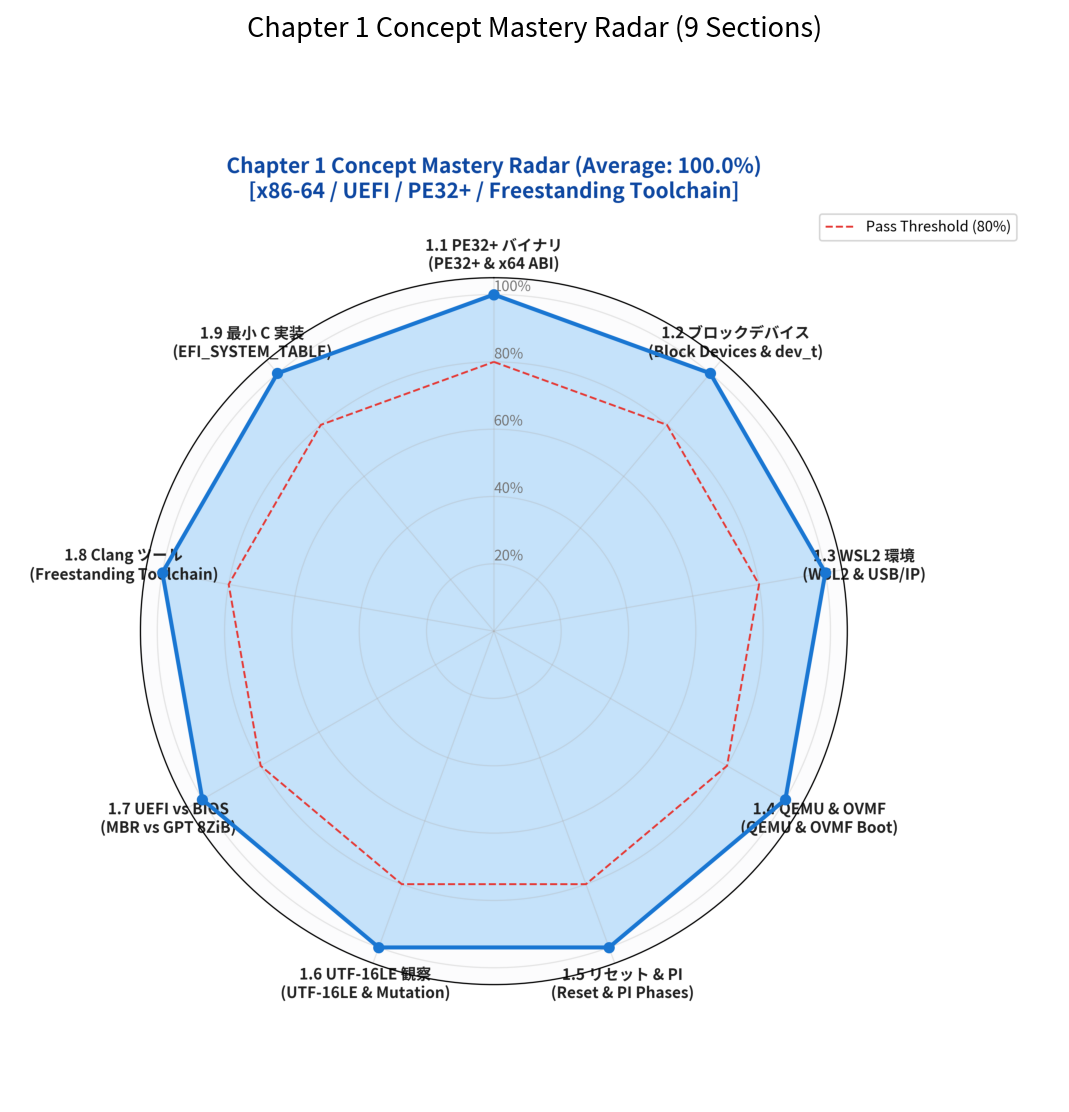

In [13]:
from common import plot_chapter1_mastery_radar

# 理解度レーダーチャートの生成と表示
radar_path = "result/fig1_ex2_ch1_mastery_radar.png"
plot_chapter1_mastery_radar(radar_path, result["mastery_rates"])

img_radar = Image.open(radar_path)
plt.figure(figsize=(9, 9), dpi=150)
plt.imshow(img_radar)
plt.axis("off")
plt.title("Chapter 1 Concept Mastery Radar (9 Sections)", fontsize=13, pad=10)
plt.show()


---

## 🏆 第1章 総括と第2章への展望

おめでとうございます！これで第1章「**PCの仕組みとハローワールド**」の全9節と演習問題をすべて完遂しました。

### 本章で身につけた武器・アーキテクチャ理解
1. **UEFI ブートローダの最小骨格**:
   - 16進ダンプによるバイナリ直打ち（`BOOTX64.EFI`）から、PE32+/COFFヘッダ構造、Microsoft x64 ABI のシャドウスペースと16バイトスタック整列の数理を完全に掴みました。
2. **ハードウェアとファームウェアの対話**:
   - CPUリセットベクタ（`0xFFFFFFF0`）からの命令フェッチ、UEFI Platform Initialization (PI) の各フェーズ（SEC $\to$ PEI $\to$ DXE $\to$ BDS）、および FAT32 ファイルシステムからの自動探索パス（`\EFI\BOOT\BOOTX64.EFI`）を理解しました。
3. **レガシーBIOSから現代UEFIへのパラダイムシフト**:
   - 16ビットリアルモードと A20 ゲートの呪縛、MBR の 32ビット LBA 2TiB 限界を、GPT の 64ビット LBA 8ZiB と 64ビット Long Mode の利点と対比して論理的に把握しました。
4. **フリースタンディング開発ツールチェーン**:
   - `-target x86_64-unknown-windows`, `-ffreestanding`, `-mno-red-zone`, `-fshort-wchar` などのフラグの必然性と、ホストOS非依存バイナリの生成手法を修得しました。
5. **最小 C 言語実装と EFI_SYSTEM_TABLE**:
   - アセンブリを使わず、64ビットポインタ演算と構造体定義のみで `ConOut->OutputString` を呼び出し画面に文字を出すベアメタル C プログラミングの極意を学びました。

---

### 次なるステージ: 第2章「EDK II入門とメモリマップ」
次章（第2章）では、UEFI の公式開発フレームワークである **EDK II (TianoCore)** を本格導入します：
- EDK II パッケージ構成（`.dec`, `.dsc`, `.inf`）とビルドシステムの全貌
- `MikanLoaderPkg` の構築と `UefiMain` の記述
- OS カーネルの生命線となる **メインメモリマップの取得 (`GetMemoryMap()`)**
- UEFI メモリディスクリプタの走査、物理アドレスとページ数の計算、ポインタとアロー演算子

いよいよ本格的な自作ブートローダの開発が始まります！
